Exploratory Data Analysis - Ở đây chúng ta cần phải hiểu dữ liệu trước khi huấn luyện : Có bao nhiêu loại cây ? Các cây sống trong môi trường nhiệt độ, độ pH, và lượng mưa như thế nào , những đặc trưng nào có mối tương quan?

1 - Đọc dữ liệu

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

BASE_DIR = Path.cwd().parent

df = pd.read_csv(
    BASE_DIR / "data" / "Crop_recommendation.csv"
)

features = [
    "N", "P", "K",
    "temperature", "humidity",
    "ph", "rainfall"
]

print(df.head())
print("So loai cay:", df["label"].nunique())


    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice
So loai cay: 22


2 - Vẽ số lượng mẫu của từng cây - Biểu đồ này giúp kiểm tra dữ liệu có bị mất cân bằng giữa các lớp cây trồng hay không?

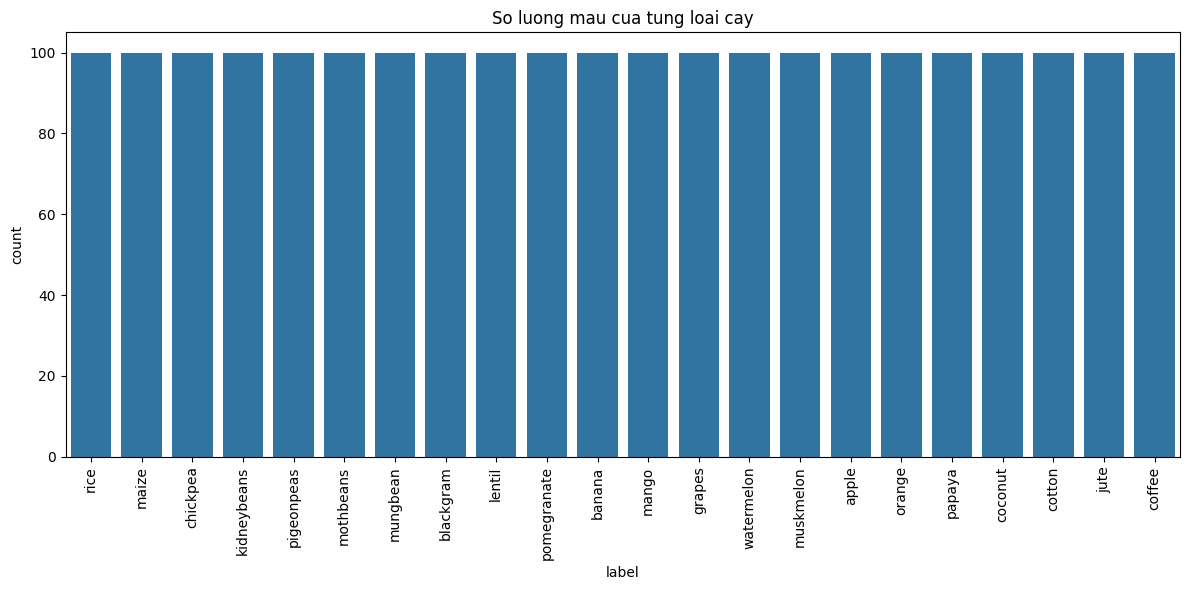

In [2]:

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="label",
    order=df["label"].value_counts().index
)

plt.xticks(rotation=90)
plt.title("So luong mau cua tung loai cay")
plt.tight_layout()
plt.show()


3 - Phân tích nhiệt độ theo loại cây

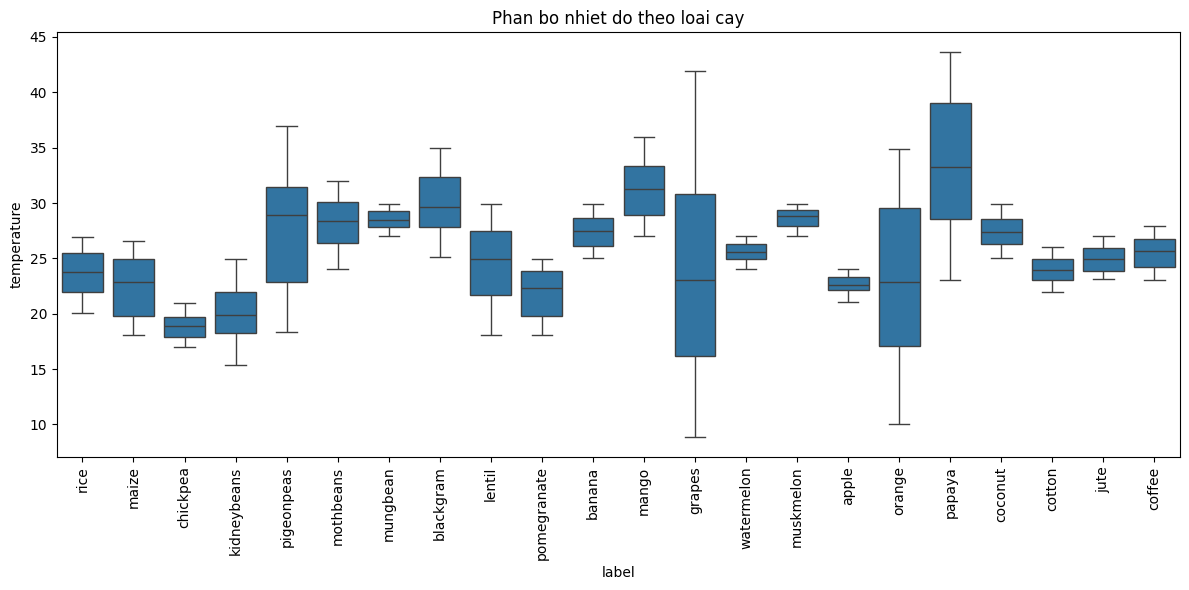

In [3]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="label",
    y="temperature"
)

plt.xticks(rotation=90)
plt.title("Phan bo nhiet do theo loai cay")
plt.tight_layout()
plt.show()


4 - Phân tích pH theo loại cây 


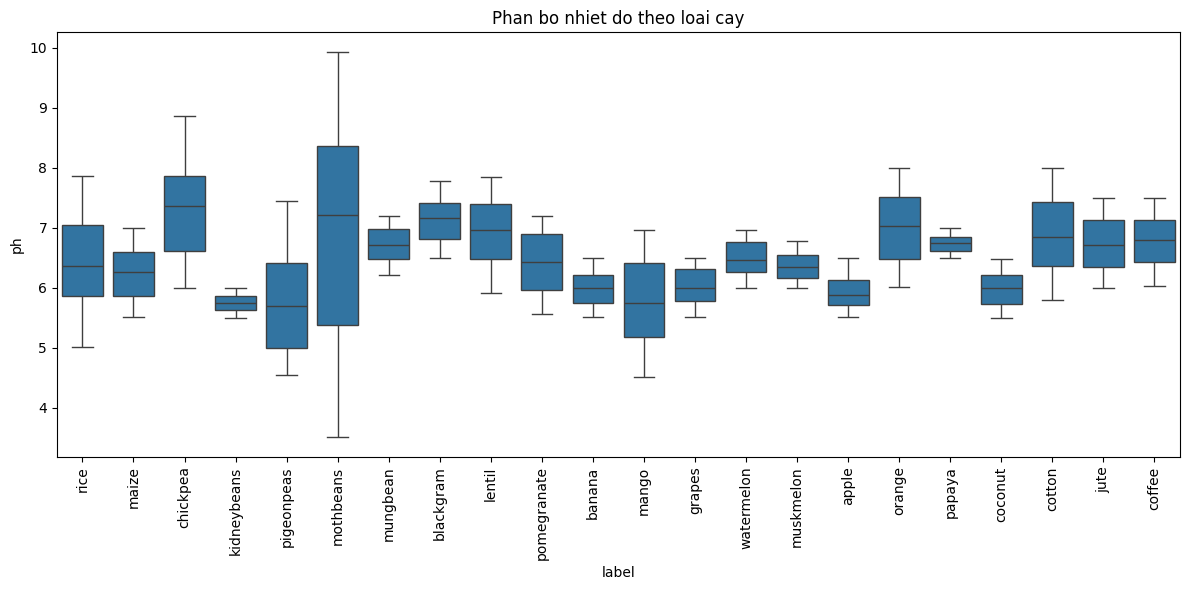

In [ ]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="label",
    y="ph"
)

plt.xticks(rotation=90)
plt.title("Phân bổ độ pH theo loại cây")
plt.tight_layout()
plt.show()


5 - Phân tích độ ẩm theo loại cây 

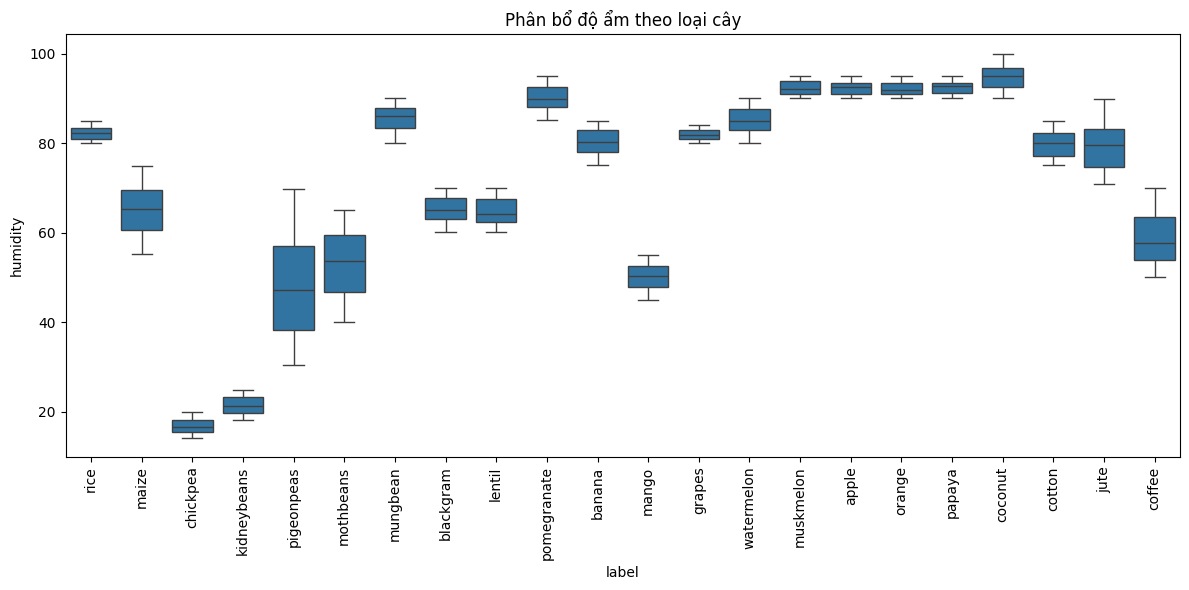

In [6]:

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="label",
    y="humidity"
)

plt.xticks(rotation=90)
plt.title("Phân bổ độ ẩm theo loại cây")
plt.tight_layout()
plt.show()


6 - Phân bổ lượng mưa theo loại cây 

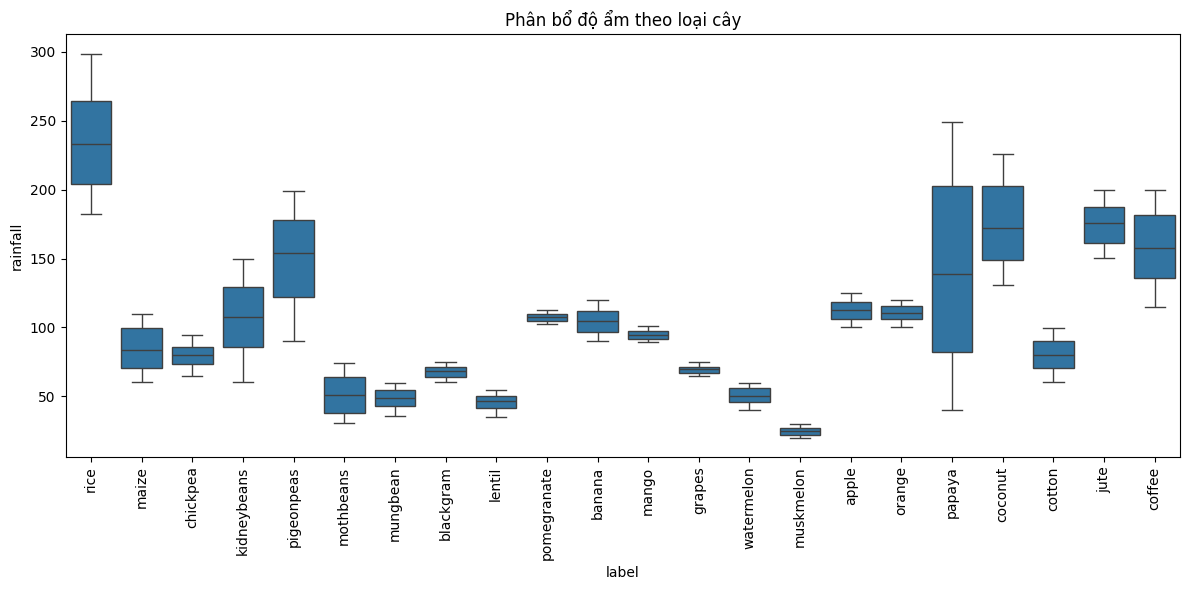

In [7]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="label",
    y="rainfall"
)

plt.xticks(rotation=90)
plt.title("Phân bổ độ ẩm theo loại cây")
plt.tight_layout()
plt.show()


Ta có thể thêm các biểu đồ cho N,P,K bằng việc thay các feature - y tương ứng

7 - Ma trận tương quan

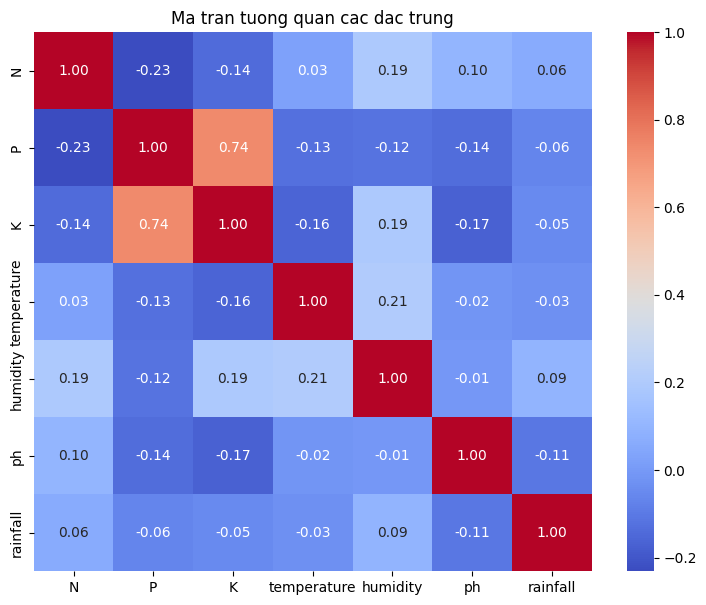

In [8]:

plt.figure(figsize=(9, 7))

sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Ma tran tuong quan cac dac trung")
plt.show()


Kết quả thống kê mô tả cho thấy cả 7 đặc trưng đầu vào đều có 2.200 giá trị hợp lệ. Điều này cho thấy không có giá trị thiếu được Pandas nhận diện trong các cột đặc trưng dạng số.

Các chỉ số dinh dưỡng N, P, K đều có giá trị không âm. Độ ẩm nằm trong khoảng 14,26% đến 99,98%, còn độ pH dao động từ 3,50 đến 9,94. Các khoảng giá trị này không thể hiện sự vi phạm hiển nhiên đối với những giới hạn vật lý cơ bản.

Tuy nhiên, cần tiếp tục kiểm tra các bản ghi trùng lặp, giá trị bất thường và sự nhất quán của nhãn cây trồng trước khi huấn luyện mô hình.

Nhìn chung, tập dữ liệu có cấu trúc thuận lợi cho quá trình phân tích và xây dựng mô hình phân loại.


CÁC ĐẶC TRƯNG
Đặc trưng nhiệt độ: Nhiệt độ trung bình của các mẫu là 25,62°C, với độ lệch chuẩn khoảng 5,06°C. Giá trị nhiệt độ thấp nhất là 8,83°C và cao nhất là 43,68°C. Điều này cho thấy tập dữ liệu bao gồm nhiều điều kiện nhiệt độ khác nhau, tạo cơ sở để mô hình học được sự khác biệt về điều kiện khí hậu giữa các loại cây trồng.

Đặc trưng độ ẩm: Độ ẩm trung bình đạt 71,48%, với độ lệch chuẩn 22,26%. Giá trị trải rộng từ 14,26% đến 99,98%, cho thấy các mẫu dữ liệu có sự khác biệt đáng kể về điều kiện độ ẩm.

Đặc trưng pH: Độ pH trung bình đạt 6,47 và độ lệch chuẩn là 0,77. Phạm vi pH từ 3,50 đến 9,94 cho thấy bộ dữ liệu có các mẫu thuộc nhiều điều kiện đất khác nhau, từ đất có tính axit đến đất có tính kiềm.

Đặc trưng lượng mưa: Lượng mưa trung bình là 103,46 mm, với độ lệch chuẩn 54,96 mm. Giá trị nhỏ nhất và lớn nhất lần lượt là 20,21 mm và 298,56 mm. Đây là đặc trưng có phạm vi giá trị khá rộng, có thể cung cấp thông tin hữu ích để phân biệt các nhóm cây trồng.

Các đặc trưng dinh dưỡng đất: Ba chỉ số N, P, K có phạm vi và mức độ phân tán khác nhau. Đặc biệt, K có độ lệch chuẩn 50,65, lớn hơn giá trị trung bình 48,15, cho thấy mức độ biến thiên tương đối lớn của đặc trưng này trong tập dữ liệu.